In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [6]:
import os

print("Notebook is running from:")
print(os.getcwd())

print("\nFiles in this folder:")
print(os.listdir())

Notebook is running from:
C:\Users\kavya\Inflation Research Abstracts Classification

Files in this folder:
['.ipynb_checkpoints', 'dataset', 'Inflation_Abstracts_EDA.ipynb']


In [8]:
import json

with open("dataset/inflation+research+abstracts+classification/classified_abstracts.json", "r", encoding="utf-8") as file:
    data = json.load(file)

df = pd.DataFrame(data)

print("Dataset loaded successfully!")
print("Shape:", df.shape)

Dataset loaded successfully!
Shape: (1138, 3)


In [10]:
df.head()

,DOI,Abstract,Label
0,10.1155/2021/1071145,Forward-looking forecasting of the inflation r...,1
1,10.1007/s43546-022-00384-2,Our study examined the disaggregation of infla...,1
2,10.1002/for.2667,This paper develops a dynamic factor model tha...,0
3,10.1007/s42973-021-00091-x,"In this paper, I use a simple SIR Macro model ...",0
4,10.1007/s40258-012-0003-z,BackgroundGame theory is useful for identifyin...,0


In [11]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1138 entries, 0 to 1137
Data columns (total 3 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   DOI       1134 non-null   object
 1   Abstract  1138 non-null   object
 2   Label     1138 non-null   object
dtypes: object(3)
memory usage: 26.8+ KB


In [12]:
df.describe(include="all")

,DOI,Abstract,Label
count,1134,1138,1138
unique,1134,1125,2
top,10.1017/s1365100504030202,Expectations play a crucial role in modern mac...,0
freq,1,2,900


In [13]:
print("Missing values in each column:")
print(df.isnull().sum())

Missing values in each column:
DOI         4
Abstract    0
Label       0
dtype: int64


In [14]:
print("Number of duplicate rows:", df.duplicated().sum())

Number of duplicate rows: 2


In [15]:
print("Label distribution:")
print(df["Label"].value_counts())

print("\nLabel percentages:")
print(df["Label"].value_counts(normalize=True) * 100)

Label distribution:
Label
0    900
1    238
Name: count, dtype: int64

Label percentages:
Label
0    79.086116
1    20.913884
Name: proportion, dtype: float64


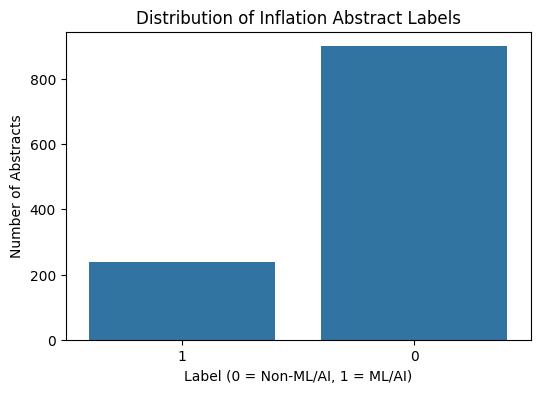

In [16]:
plt.figure(figsize=(6, 4))

sns.countplot(data=df, x="Label")

plt.title("Distribution of Inflation Abstract Labels")
plt.xlabel("Label (0 = Non-ML/AI, 1 = ML/AI)")
plt.ylabel("Number of Abstracts")
plt.show()

In [17]:
df["Abstract_Length"] = df["Abstract"].astype(str).apply(len)

print(df["Abstract_Length"].describe())

count     1138.000000
mean      1145.284710
std        687.242316
min        113.000000
25%        777.250000
50%       1021.000000
75%       1333.750000
max      14076.000000
Name: Abstract_Length, dtype: float64


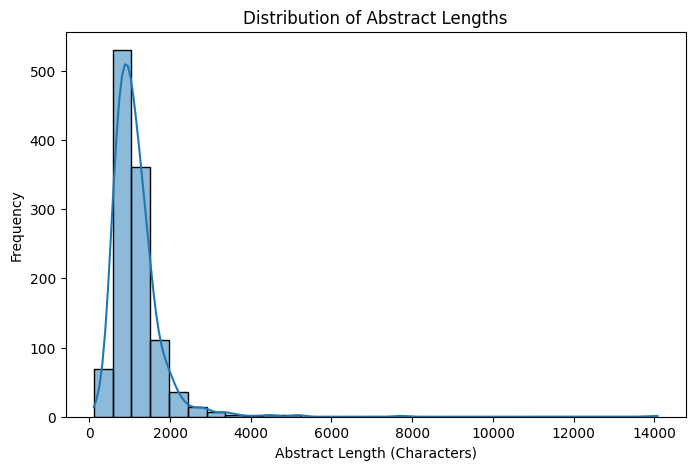

In [18]:
plt.figure(figsize=(8, 5))

sns.histplot(data=df, x="Abstract_Length", bins=30, kde=True)

plt.title("Distribution of Abstract Lengths")
plt.xlabel("Abstract Length (Characters)")
plt.ylabel("Frequency")
plt.show()

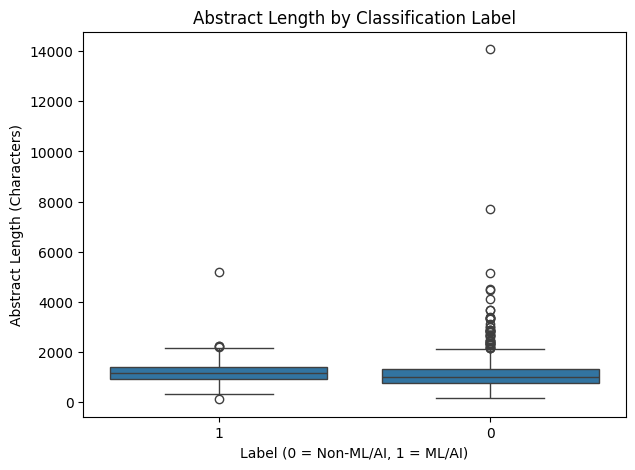

In [19]:
plt.figure(figsize=(7, 5))

sns.boxplot(data=df, x="Label", y="Abstract_Length")

plt.title("Abstract Length by Classification Label")
plt.xlabel("Label (0 = Non-ML/AI, 1 = ML/AI)")
plt.ylabel("Abstract Length (Characters)")
plt.show()

In [20]:
print("Sample abstracts with Label 0:")
display(df[df["Label"] == 0][["Abstract", "Label"]].head(2))

print("\nSample abstracts with Label 1:")
display(df[df["Label"] == 1][["Abstract", "Label"]].head(2))

Sample abstracts with Label 0:


,Abstract,Label



Sample abstracts with Label 1:


,Abstract,Label


## Result
Exploratory Data Analysis (EDA) was performed on the Inflation Research Abstracts Classification dataset containing 1,138 scientific paper abstracts related to inflation economics. The dataset was inspected for its structure, data types, missing values, duplicate records, and target class distribution. Abstract lengths were analyzed using statistical summaries and visualizations.

## Conclusion
The dataset contains textual abstracts and a binary target label indicating whether an article relates to machine learning or artificial intelligence methodologies. The dataset was explored successfully and is suitable for text classification. The findings will be used in the next stage for text preprocessing and preparation.